<!-- colab-badge -->
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Zeshengliu213/ai-for-materials/blob/main/07%20-%20Neural%20Networks%20and%20CNNs/07a_neural_networks.ipynb)

# 07a · 神经网络入门：从一个神经元到多层感知机

> 对应 ai4chem `03 - Intro to Deep Learning` 的 `01_intro_to_dl.ipynb`。原课程用 PyTorch Lightning 和 wandb；这里只用纯 PyTorch，训练循环一行一行写出来，看得见每一步在做什么。

1. 为什么要"深"？神经元和激活函数
2. PyTorch 基础：张量和自动求导
3. 手写梯度下降：让电脑自己"拟合"一条直线
4. Python 的类（class）和 `nn.Module`
5. 搭建并训练第一个神经网络
6. 过拟合、早停、Dropout 和权重衰减
7. 学习率

### 这个 notebook 怎么用

| 标记 | 意思 | 你要做什么 |
|---|---|---|
| 📘 | 讲解 | 读一读 |
| 🤔 | 先猜一猜 | **运行之前**先想想会输出什么 |
| ▶️ | 运行看看 | 选中代码格，按 `Shift + Enter` |
| ✏️ | 改一改 | 改代码里标了 `# ✏️` 的地方，再运行 |
| 🏋️ | 练习 | 自己写代码；参考答案在 `solutions/` 文件夹 |
| 💡 | 小贴士 | 有用但不是必须记住的东西 |

In [ ]:
# colab-setup (本地运行时自动跳过)
import os, sys

if "google.colab" in sys.modules:
    _repo_dir = "/content/ai-for-materials"
    if not os.path.exists(_repo_dir):
        os.system("git clone --depth 1 https://github.com/Zeshengliu213/ai-for-materials.git " + _repo_dir)
    os.chdir(os.path.join(_repo_dir, "07 - Neural Networks and CNNs"))
    get_ipython().run_line_magic("pip", "install -q rdkit")


In [1]:
try:
    import rdkit
except ImportError:
    %pip install -q rdkit
    import rdkit

import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from rdkit import Chem, RDLogger
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RDLogger.DisableLog("rdApp.*")
print("PyTorch 版本:", torch.__version__)


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "c:\Users\18101\anaconda3\envs\zesheng\lib\runpy.py", line 196, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "c:\Users\18101\anaconda3\envs\zesheng\lib\runpy.py", line 86, in _run_code
    exec(code, run_globals)
  File "c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.s

PyTorch 版本: 2.2.2


💡 Colab 已经预装了 PyTorch。本地没有的话，按 [pytorch.org](https://pytorch.org/get-started/locally/) 的说明安装 CPU 版就够了，这一部分不需要 GPU。

📘 神经网络的训练里有很多随机性：初始权重是随机的，每一轮打乱数据的顺序也是随机的。固定**随机种子**，每次运行才能得到一样的结果。

In [2]:
def set_seed(seed=0):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.use_deterministic_algorithms(True)   # 有些运算默认每次结果略有不同，这一行让它们也固定下来

set_seed(0)

In [3]:
import os
import pandas as pd

# 本地运行：数据在 data/ 文件夹里
# Colab 运行：如果找不到文件，会弹出上传按钮，选择 solubility.csv 即可
DATA_FILE = "data/solubility.csv"
if not os.path.exists(DATA_FILE):
    DATA_FILE = "solubility.csv"
if not os.path.exists(DATA_FILE):
    try:
        from google.colab import files
        print("请上传 solubility.csv")
        files.upload()
    except ImportError:
        raise FileNotFoundError("找不到 solubility.csv，请把它放在 data/ 文件夹或和 notebook 同一个文件夹里")

df = pd.read_csv(DATA_FILE)
print("读取成功！一共", len(df), "个分子")

读取成功！一共 9482 个分子


In [4]:
df["mol"] = df["SMILES"].apply(Chem.MolFromSmiles)
df = df[df["mol"].notna()].reset_index(drop=True)

feature_cols = ["MolWt", "MolLogP", "MolMR", "HeavyAtomCount", "NumHAcceptors", "NumHDonors",
                "NumHeteroatoms", "NumRotatableBonds", "NumValenceElectrons", "NumAromaticRings",
                "NumSaturatedRings", "NumAliphaticRings", "RingCount", "TPSA", "LabuteASA",
                "BalabanJ", "BertzCT"]
X = df[feature_cols].values
y = df["Solubility"].values
print("分子数:", len(df), " 特征数:", X.shape[1])

分子数: 9480  特征数: 17


---
## 1. 为什么要"深"？

📘 第二部分的模型（线性回归、kNN、随机森林）已经不错了：随机森林的测试 RMSE 约 1.17。那为什么还要神经网络？

- **表达能力**：神经网络理论上可以逼近任意连续函数（万能逼近定理）。
- **自己学特征**：这是最关键的一点。第二部分所有的特征（描述符、指纹）都是**人设计**的。深度学习可以直接从原始结构（比如分子图，见 10a）中**学出**特征。
- **可扩展**：数据越多，大模型的优势越明显。图像、语言、蛋白质结构预测（AlphaFold）的突破都来自深度学习。

当然也有代价：需要更多数据、更多计算、更多调参，而且更难解释。**在小数据、表格型特征上，随机森林常常和神经网络打平甚至更好。** 这一节我们就会亲眼看到这一点。

### 1.1 一个神经元

📘 一个**神经元**做两件事：

1. 对输入做加权求和再加偏置：$z = w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b$，这就是线性回归；
2. 把 $z$ 送进一个**非线性**的**激活函数** $\sigma$：输出 $a = \sigma(z)$。

很多神经元并排组成一**层**，很多层叠起来就是**多层感知机**（MLP，multilayer perceptron）。"深度"指的就是层数多。

```
输入层          隐藏层 1        隐藏层 2        输出层
(17 个描述符)   (64 个神经元)   (64 个神经元)   (logS)
  x1 ──┐
  x2 ──┼──►    ○ ○ ○ … ○  ──►  ○ ○ ○ … ○  ──►   ○
  …    │       每个 ○ = 加权求和 + 激活函数
  x17 ─┘
```

### 1.2 激活函数

▶️ 常见的三个激活函数：

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


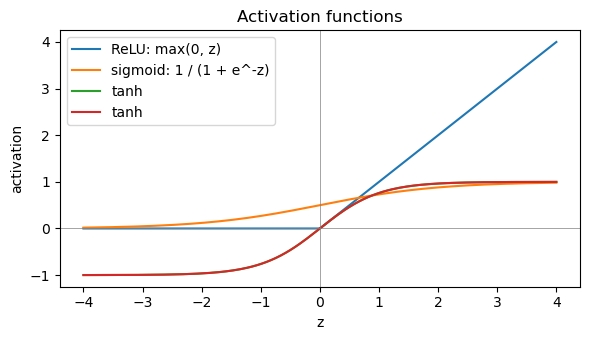

In [11]:
import numpy as np
import torch
import matplotlib.pyplot as plt
z = torch.linspace(-4, 4, 200)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(z.tolist(), torch.relu(z).tolist(), label="ReLU: max(0, z)")
ax.plot(z.tolist(), torch.sigmoid(z).tolist(), label="sigmoid: 1 / (1 + e^-z)")
ax.plot(z.tolist(), torch.tanh(z).tolist(), label="tanh")
%pip install "numpy<2"
ax.plot(z.tolist(), torch.tanh(z).tolist(), label="tanh")
ax.axhline(0, color="gray", lw=0.5); ax.axvline(0, color="gray", lw=0.5)
ax.set_xlabel("z"); ax.set_ylabel("activation"); ax.legend(); ax.set_title("Activation functions")
plt.tight_layout(); plt.show()

🤔 如果**不用**激活函数，把 10 层线性层叠起来，模型会比 1 层线性回归更强吗？

📘 不会。线性函数套线性函数还是线性函数：$W_2(W_1 x + b_1) + b_2 = (W_2 W_1) x + (W_2 b_1 + b_2)$。叠多少层都等价于**一个**线性回归。**非线性的激活函数是神经网络"变强"的关键。**

ReLU 最简单（负数变 0，正数不变），训练起来也快，是现在最常用的选择。

---
## 2. PyTorch 基础

### 2.1 张量（tensor）

📘 PyTorch 里的基本数据类型是**张量**，可以把它看成能在 GPU 上运行、还能自动求导的 NumPy 数组。用法和 NumPy 几乎一样。

In [12]:
a = torch.tensor([[1.0, 2.0, 3.0],
                  [4.0, 5.0, 6.0]])
print(a)
print("形状:", a.shape, " 数据类型:", a.dtype)
print("每列求和:", a.sum(dim=0))
print("矩阵乘法 a @ a.T:\n", a @ a.T)

tensor([[1., 2., 3.],
        [4., 5., 6.]])
形状: torch.Size([2, 3])  数据类型: torch.float32
每列求和: tensor([5., 7., 9.])
矩阵乘法 a @ a.T:
 tensor([[14., 32.],
        [32., 77.]])


In [17]:
# NumPy 和 PyTorch 互相转换
x_np = np.array([1.5, 2.5])
x_t = torch.tensor(x_np, dtype=torch.float32)   # 神经网络一般用 float32
print(x_t, "->", np.asarray(x_t.tolist()))

tensor([1.5000, 2.5000]) -> [1.5 2.5]


### 2.2 自动求导（autograd）

📘 训练神经网络的核心是**求导**：知道"损失函数对每个参数的导数"，就知道每个参数该往哪个方向调。几百万个参数手算导数是不可能的，PyTorch 可以**自动**算。

给张量加上 `requires_grad=True`，PyTorch 就会记住它参与过的每一步运算。调用 `.backward()` 之后，导数就存在 `.grad` 里。

🤔 $f(x) = x^2 + 3x$，在 $x = 2$ 处的导数是多少？先手算，再运行。

In [18]:
x = torch.tensor(2.0, requires_grad=True)
f = x**2 + 3 * x
f.backward()          # 求导
print("f(2) =", f.item())
print("df/dx at x=2:", x.grad.item())   # 手算：2x + 3 = 7

f(2) = 10.0
df/dx at x=2: 7.0


---
## 3. 手写梯度下降

📘 有了导数，就可以做**梯度下降**：

1. 随便猜一组参数；
2. 算出预测值和损失（比如均方误差 MSE）；
3. 求损失对参数的导数（梯度）；
4. 让参数**沿梯度的反方向**走一小步：$w \leftarrow w - \eta \cdot \partial L / \partial w$。$\eta$ 叫**学习率**；
5. 重复 2–4。

我们用它拟合最简单的模型：$\log S = w \cdot \log P + b$。02c 里讲过 Yalkowsky 方程 $\log S \approx 0.5 - \log P - \dots$，所以 $w$ 应该接近 -1。

🤔 梯度下降找到的 $w$ 会接近 -1 吗？

In [19]:
logp = torch.tensor(df["MolLogP"].values, dtype=torch.float32)
logs = torch.tensor(y, dtype=torch.float32)

w = torch.tensor(0.0, requires_grad=True)   # 1. 随便猜：w = 0, b = 0
b = torch.tensor(0.0, requires_grad=True)
learning_rate = 0.01                        # ✏️ 试试 0.001 和 0.1

losses = []
for step in range(300):
    pred = w * logp + b                     # 2. 预测
    loss = ((pred - logs) ** 2).mean()      #    损失：MSE
    loss.backward()                         # 3. 求梯度
    with torch.no_grad():                   # 4. 更新参数（这一步不需要求导）
        w -= learning_rate * w.grad
        b -= learning_rate * b.grad
    w.grad.zero_(); b.grad.zero_()          #    梯度会累加，用完要清零
    losses.append(loss.item())

print(f"梯度下降: w = {w.item():.3f}, b = {b.item():.3f}")
print("最小二乘 (np.polyfit):", np.polyfit(df["MolLogP"], y, 1).round(3))

梯度下降: w = -0.408, b = -2.061
最小二乘 (np.polyfit): [-0.406 -2.083]


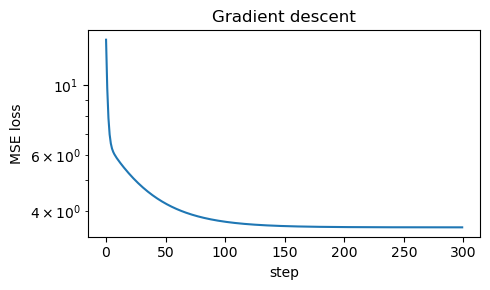

In [20]:
plt.figure(figsize=(5, 3))
plt.plot(losses)
plt.xlabel("step"); plt.ylabel("MSE loss"); plt.yscale("log"); plt.title("Gradient descent")
plt.tight_layout(); plt.show()

📘 梯度下降和最小二乘公式给出几乎一样的答案：$w \approx -0.41$，比 Yalkowsky 的 -1 平缓得多。原因至少有两个：AqSolDB 里有不少盐和离子化合物，它们不服从这个方程；MolLogP 是 RDKit **估算**的，不是实验值，自变量本身的误差会把拟合出的斜率"拉平"。

💡 这里的重点不是斜率，而是**电脑自己一步步把 $w$、$b$ 从 0 调到了最优值**。

✏️ 把学习率改成 0.1 再运行。损失会怎样？

📘 学习率太大，每一步都"跨过"了最低点，越跳越远，损失变成 `nan` 或无穷大（**发散**）。太小则要走很多很多步。第 7 节会再看这个问题。

💡 **神经网络的训练就是这个循环，只是参数从 2 个变成了几千、几百万个。** 下面所有代码都是这 5 步的不同包装。

---
## 4. Python 的类和 `nn.Module`

📘 PyTorch 里的模型都写成**类**（class）。类是一个"模板"，规定一种东西**有什么数据**（属性）和**能做什么**（方法）。用模板造出来的具体东西叫**实例**。

举个化学的例子：

In [21]:
class Molecule:
    def __init__(self, name, smiles):       # 创建实例时自动调用，self 指"这个实例自己"
        self.name = name                     # 属性
        self.smiles = smiles
        self.mol = Chem.MolFromSmiles(smiles)

    def n_heavy_atoms(self):                 # 方法
        return self.mol.GetNumHeavyAtoms()

    def describe(self):
        return f"{self.name}: {self.smiles}, {self.n_heavy_atoms()} heavy atoms"

thiophene = Molecule("thiophene", "c1ccsc1")      # 用模板造出两个实例
pentacene = Molecule("pentacene", "c1ccc2cc3cc4cc5ccccc5cc4cc3cc2c1")
print(thiophene.describe())
print(pentacene.describe())

thiophene: c1ccsc1, 5 heavy atoms
pentacene: c1ccc2cc3cc4cc5ccccc5cc4cc3cc2c1, 22 heavy atoms


📘 还有一个概念叫**继承**：`class B(A)` 表示 B 自动拥有 A 的所有本领，只需要补上自己特有的部分。

PyTorch 的模型都继承自 `nn.Module`。`nn.Module` 已经帮我们处理好了参数管理、求导、保存和加载等杂事，我们只需要写两件事：

- `__init__`：模型有哪些层；
- `forward`：数据怎么从输入流到输出。

### 🏋️ 练习 07a-1

给 `Molecule` 类加一个方法 `n_aromatic_rings()`，返回芳香环的数目（提示：`from rdkit.Chem import Descriptors`，然后 `Descriptors.NumAromaticRings(self.mol)`）。对噻吩和并五苯分别调用一次。

In [ ]:
# 在这里写你的代码

---
## 5. 搭建并训练第一个神经网络

### 5.1 数据：训练集、验证集、测试集

📘 测试集和第二部分**完全一样**（`test_size=0.2, random_state=42`），这样结果可以直接和随机森林比较。

神经网络训练时要不断决定"训练到什么时候停"、"用多大的网络"，这些决定不能看测试集（否则就是 02b 讲的数据泄漏）。所以从训练集里再分出 10% 作为**验证集**（validation set），专门用来做这些决定。

| 集合 | 用途 | 大约多少 |
|---|---|---|
| 训练集 | 更新参数 | 72% |
| 验证集 | 选超参数、决定何时停止 | 8% |
| 测试集 | 最后**只看一次**，报告结果 | 20% |

In [22]:
X_trval, X_test, y_trval, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(X_trval, y_trval, test_size=0.1, random_state=42)
print("训练:", len(X_train), " 验证:", len(X_valid), " 测试:", len(X_test))

scaler = StandardScaler().fit(X_train)     # 和 kNN 一样，神经网络也需要缩放；只在训练集上 fit

def to_tensor(a):
    return torch.tensor(a, dtype=torch.float32)

Xtr, Xva, Xte = (to_tensor(scaler.transform(a)) for a in (X_train, X_valid, X_test))
ytr, yva, yte = (to_tensor(a) for a in (y_train, y_valid, y_test))

训练: 6825  验证: 759  测试: 1896


💡 为什么神经网络需要缩放？BertzCT 的数值上千，NumHDonors 只有 0–5。不缩放的话，梯度几乎全被大数值的特征"带着走"，训练会很慢甚至不收敛。

### 5.2 小批量（mini-batch）

📘 第 3 节每一步都用了**全部** 9480 个分子算梯度。数据更大时这样太慢，通常每次只取一小批（比如 64 个）算梯度、更新一次参数。把所有数据都过一遍叫一个 **epoch**（轮）。

`DataLoader` 负责把数据切成小批，每个 epoch 重新打乱一次。

In [23]:
from torch.utils.data import DataLoader, TensorDataset

train_loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=64, shuffle=True)

xb, yb = next(iter(train_loader))   # 取出第一个小批看看
print("一个小批的 X:", xb.shape, " y:", yb.shape)
print("每个 epoch 有", len(train_loader), "个小批，也就是更新", len(train_loader), "次参数")

一个小批的 X: torch.Size([64, 17])  y: torch.Size([64])
每个 epoch 有 107 个小批，也就是更新 107 次参数


### 5.3 定义模型

📘 我们的 MLP：17 个输入 → 64 个神经元 → 64 个神经元 → 1 个输出（logS）。

In [24]:
class SolubilityMLP(nn.Module):
    def __init__(self, n_features, hidden_size=64, dropout=0.0):
        super().__init__()                   # 先让 nn.Module 做好它的准备工作
        self.net = nn.Sequential(
            nn.Linear(n_features, hidden_size),
            nn.ReLU(),
            nn.Dropout(dropout),              # 第 6 节再讲；dropout=0 时什么也不做
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(1)         # 形状 (batch, 1) -> (batch,)

set_seed(0)
model = SolubilityMLP(n_features=17)
print(model)

SolubilityMLP(
  (net): Sequential(
    (0): Linear(in_features=17, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.0, inplace=False)
    (3): Linear(in_features=64, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.0, inplace=False)
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)


🤔 这个网络一共有多少个参数？提示：`nn.Linear(17, 64)` 有 17×64 个权重和 64 个偏置。

In [25]:
n_params = sum(p.numel() for p in model.parameters())
print("参数总数:", n_params)   # (17*64 + 64) + (64*64 + 64) + (64*1 + 1)

参数总数: 5377


📘 5377 个参数，而训练集只有约 6800 个分子。第二部分的线性回归只有 18 个参数。参数多，表达能力强，但也更容易过拟合（第 6 节）。

### 5.4 训练循环

📘 和第 3 节的 5 步完全对应，只是：

- 损失函数用现成的 `nn.MSELoss()`；
- 参数更新交给**优化器**。`Adam` 是最常用的一种，它会给每个参数自动调整步长，比第 3 节的"朴素"梯度下降稳得多。

| 第 3 节手写 | 这里 |
|---|---|
| `pred = w * logp + b` | `pred = model(xb)` |
| `loss = ((pred - y)**2).mean()` | `loss = loss_fn(pred, yb)` |
| `loss.backward()` | `loss.backward()` |
| `w -= lr * w.grad` | `optimizer.step()` |
| `w.grad.zero_()` | `optimizer.zero_grad()` |

In [26]:
loss_fn = nn.MSELoss()

def train_one_epoch(model, loader, optimizer):
    model.train()                            # 训练模式（Dropout 生效）
    for xb, yb in loader:
        loss = loss_fn(model(xb), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

def rmse(model, X, y):
    model.eval()                             # 评估模式（Dropout 关闭）
    with torch.no_grad():                    # 评估时不需要求导，更快也更省内存
        return torch.sqrt(loss_fn(model(X), y)).item()

def fit(model, n_epochs=100, lr=1e-3, weight_decay=0.0):
    """训练 n_epochs 轮。返回每一轮的训练/验证 RMSE，以及验证集上最好的那一轮的参数。"""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {"train": [], "valid": []}
    best_valid, best_state = float("inf"), None
    for epoch in range(n_epochs):
        train_one_epoch(model, train_loader, optimizer)
        history["train"].append(rmse(model, Xtr, ytr))
        history["valid"].append(rmse(model, Xva, yva))
        if history["valid"][-1] < best_valid:      # 记下验证集上最好的参数（第 6 节用）
            best_valid = history["valid"][-1]
            best_state = copy.deepcopy(model.state_dict())
    return history, best_state

def plot_history(history, title=""):
    fig, ax = plt.subplots(figsize=(5.5, 3.5))
    ax.plot(history["train"], label="train")
    ax.plot(history["valid"], label="validation")
    best = int(np.argmin(history["valid"]))
    ax.axvline(best, color="gray", ls=":", label=f"best epoch ({best})")
    ax.set_xlabel("epoch"); ax.set_ylabel("RMSE (logS)"); ax.set_title(title); ax.legend()
    plt.tight_layout(); plt.show()

▶️ 训练 100 个 epoch（大约 10–20 秒）：

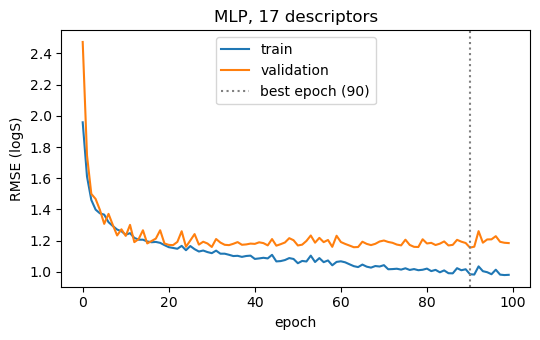

最后一轮: 训练 RMSE = 0.98, 验证 RMSE = 1.18


In [27]:
set_seed(0)
mlp = SolubilityMLP(n_features=17)
history, best_state = fit(mlp, n_epochs=100)
plot_history(history, "MLP, 17 descriptors")
print(f"最后一轮: 训练 RMSE = {history['train'][-1]:.2f}, 验证 RMSE = {history['valid'][-1]:.2f}")

📘 训练 RMSE 一路下降。验证 RMSE 一开始也跟着降，后来停住甚至轻微上升：模型开始记住训练集的细节了。

现在看测试集：

In [28]:
print(f"MLP 测试 RMSE: {rmse(mlp, Xte, yte):.2f}")
print("对照（第二部分）: 线性回归 1.64，kNN（缩放）1.24，随机森林 1.17")

MLP 测试 RMSE: 1.19
对照（第二部分）: 线性回归 1.64，kNN（缩放）1.24，随机森林 1.17


📘 和随机森林差不多。这正是第 1 节说的：**同样的 17 个手工特征，换成神经网络不会有奇迹。** 神经网络真正的优势要等 10a 换成分子图时才显现出来。

▶️ 画一张对角线图（parity plot）：

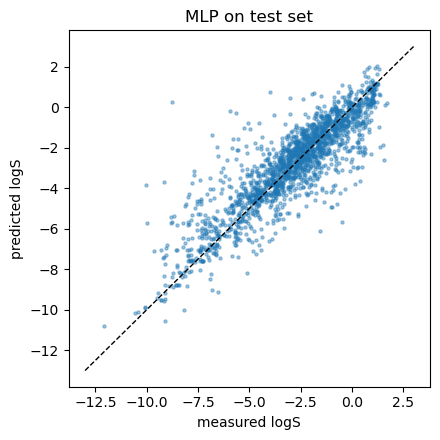

In [30]:
mlp.eval()
with torch.no_grad():
    y_test = yte.tolist()
    y_pred = mlp(Xte).tolist()

plt.figure(figsize=(4.5, 4.5))
plt.scatter(y_test, y_pred, s=5, alpha=0.4)
plt.plot([-13, 3], [-13, 3], "k--", lw=1)
plt.xlabel("measured logS"); plt.ylabel("predicted logS"); plt.title("MLP on test set")
plt.tight_layout(); plt.show()

---
## 6. 过拟合和三种对策

### 6.1 更大的网络

🤔 把每层的神经元从 64 增加到 512（参数从 5 千变成约 27 万），训练 150 轮。测试 RMSE 会更好还是更差？

参数总数: 272385


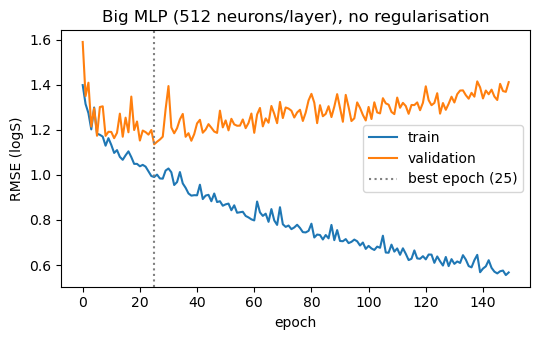

最后一轮: 训练 RMSE = 0.57, 验证 RMSE = 1.41


In [31]:
set_seed(0)
big_mlp = SolubilityMLP(n_features=17, hidden_size=512)   # ✏️
print("参数总数:", sum(p.numel() for p in big_mlp.parameters()))
big_history, big_best_state = fit(big_mlp, n_epochs=150)
plot_history(big_history, "Big MLP (512 neurons/layer), no regularisation")
print(f"最后一轮: 训练 RMSE = {big_history['train'][-1]:.2f}, 验证 RMSE = {big_history['valid'][-1]:.2f}")

📘 典型的**过拟合**：训练误差一路降到很低，验证误差在前几十轮就到了最低点，之后反而**上升**。和 02a 里不限深度的随机森林是同一个现象：模型有足够的自由度去"背答案"。

### 6.2 对策一：早停（early stopping）

📘 最简单的办法：**在验证误差最低的那一轮停下来**。`fit` 函数一直在记录那一轮的参数（`best_state`），把它装回去就行。

In [ ]:
print(f"最后一轮的模型   测试 RMSE: {rmse(big_mlp, Xte, yte):.2f}")
big_mlp.load_state_dict(big_best_state)
print(f"验证集最好的一轮 测试 RMSE: {rmse(big_mlp, Xte, yte):.2f}")

🤔 验证 RMSE 从最低点涨到了 1.44，可测试 RMSE 只差了 0.01。为什么？

📘 验证集只有 759 个分子。过拟合的模型会把**少数几个**特殊分子预测得很离谱，而 RMSE 对大误差特别敏感（误差先平方再平均），几个离谱的点就能把小集合的 RMSE 拉高很多。测试集里恰好没有那么极端的情况。

这提醒我们：**小数据集上的验证曲线噪声很大**，不要对 0.01–0.02 的差别过度解读。02b 推荐交叉验证，也是这个原因。

💡 实际中不需要真的训练完所有轮次：验证误差连续若干轮（比如 20 轮，这个数叫 *patience*）不再改善就停止训练，可以省很多时间。

### 6.3 对策二和三：Dropout 和权重衰减

📘 **Dropout**：训练时每一步**随机关掉**一部分神经元（比如 20%）。网络不能依赖某几个特定的神经元，被迫学到更"分散"、更稳健的规律。评估时（`model.eval()`）Dropout 自动关闭，所有神经元都参与。

**权重衰减**（weight decay）：在损失里加一项 $\lambda \sum w^2$，惩罚过大的权重。这和岭回归（Ridge）是同一个思路。在 Adam 里通过 `weight_decay` 参数设置。

▶️ 同样的大网络，加上两者再训练一次（约 30 秒）：

In [ ]:
set_seed(0)
reg_mlp = SolubilityMLP(n_features=17, hidden_size=512, dropout=0.2)    # ✏️ dropout
reg_history, reg_best_state = fit(reg_mlp, n_epochs=150, weight_decay=1e-4)   # ✏️ weight_decay
plot_history(reg_history, "Big MLP + dropout 0.2 + weight decay 1e-4")
print(f"最后一轮: 训练 RMSE = {reg_history['train'][-1]:.2f}, 验证 RMSE = {reg_history['valid'][-1]:.2f}")
reg_mlp.load_state_dict(reg_best_state)
print(f"早停后测试 RMSE: {rmse(reg_mlp, Xte, yte):.2f}")

📘 对比 6.1 的图：训练误差不再一路冲到很低，验证误差也不再明显回升，最后一轮的验证 RMSE 从 1.44 降到了约 1.14。**正则化让模型"不那么会背答案"**，即使忘了早停也不会跑偏太多。

把这一部分的结果放在一起：

| 模型 | 测试 RMSE |
|---|---|
| 随机森林（第二部分） | 1.17 |
| MLP 64×64 | 1.19 |
| MLP 512×512，最后一轮 | 1.18 |
| MLP 512×512，早停 | 1.17 |
| MLP 512×512，Dropout + 权重衰减 + 早停 | 1.17 |

🤔 网络大了 50 倍，加了各种技巧，测试 RMSE 几乎纹丝不动。说明什么？

📘 **瓶颈不在模型，在特征。** 17 个描述符里能挖的信息，随机森林和神经网络都已经挖得差不多了（还记得 02c 说的吗：熔点相关的信息根本不在这些特征里）。想再进一步，需要给模型**更多、更好的信息**。

💡 6.3 的训练曲线可能比 6.1 的更抖，甚至偶尔高过验证曲线：`rmse` 是在 `eval` 模式（Dropout 关闭）下算的，但参数是在 Dropout 打开的情况下学的。这是正常现象。

### 🏋️ 练习 07a-2

把 `SolubilityMLP` 里的 `nn.ReLU()` 换成 `nn.Tanh()`（写一个新类 `TanhMLP`，或者给 `SolubilityMLP` 加一个 `activation` 参数），用 64×64 的网络训练 100 轮，比较测试 RMSE。

In [ ]:
# 在这里写你的代码

---
## 7. 学习率

📘 学习率是神经网络**最重要**的超参数。第 3 节已经看到太大会发散。

▶️ 用三个学习率各训练 30 轮：

In [ ]:
fig, ax = plt.subplots(figsize=(5.5, 3.5))
for lr in [1e-1, 1e-3, 1e-5]:                 # ✏️
    set_seed(0)
    h, _ = fit(SolubilityMLP(n_features=17), n_epochs=30, lr=lr)
    ax.plot(h["valid"], label=f"lr = {lr:g}")
    print(f"lr = {lr:g}: 最后一轮验证 RMSE = {h['valid'][-1]:.2f}")
ax.set_xlabel("epoch"); ax.set_ylabel("validation RMSE"); ax.set_yscale("log"); ax.legend()
ax.set_title("Effect of learning rate"); plt.tight_layout(); plt.show()

📘

- `lr = 1e-5`：太小，30 轮后验证 RMSE 还在 3 以上，比"永远猜平均值"（2.42）还差。
- `lr = 1e-3`：Adam 的默认值，通常是个不错的起点，30 轮后约 1.18。
- `lr = 1e-1`：太大，曲线剧烈抖动，最后停在约 1.26，比 `1e-3` 差。（Adam 会自动调整步长，所以没有像第 3 节那样直接发散。）

💡 常见的经验：先用 `1e-3`；不收敛就调小到 `3e-4` 或 `1e-4`；训练太慢就调大。也可以让学习率随训练逐渐变小（learning rate scheduler），chemprop（10b）就是这么做的。

### 🏋️ 练习 07a-3

神经网络也能做分类。把任务改成 02c 的"logS < -4 是否难溶"：

- 标签 `y_cls = (y < -4)`，转成 float 张量；
- 模型结构不变（最后输出 1 个数，叫 **logit**）；
- 损失换成 `nn.BCEWithLogitsLoss()`（二分类交叉熵，内部自带 sigmoid）；
- 预测概率 = `torch.sigmoid(model(X))`。

训练 50 轮后，用 `sklearn.metrics.roc_auc_score` 算测试集的 ROC-AUC，和 02c 的随机森林（0.953）比较。

提示：要么写一个新的训练循环，要么暂时把全局的 `loss_fn` 换掉。注意测试集要用和上面一样的划分。

In [ ]:
# 在这里写你的代码

---
## 小结

| 学到了 | 代码 / 要点 |
|---|---|
| 神经元 | 线性组合 + 非线性激活函数；没有激活函数，叠多少层都是线性模型 |
| 张量 | `torch.tensor`，用法像 NumPy |
| 自动求导 | `requires_grad=True`、`.backward()`、`.grad` |
| 梯度下降 | 预测 → 损失 → 求梯度 → 沿反方向走一步 → 重复 |
| 模型 | 继承 `nn.Module`，写 `__init__` 和 `forward` |
| 训练 | `DataLoader` 小批量；`optimizer.zero_grad()`、`loss.backward()`、`optimizer.step()` |
| 三个集合 | 训练集更新参数，验证集做决定，测试集最后看一次 |
| 过拟合对策 | 早停、Dropout、权重衰减 |
| 学习率 | 最重要的超参数；Adam 从 `1e-3` 开始 |

**本节最重要的发现**：输入同样是 17 个手工描述符时，神经网络并不比随机森林好多少。要发挥深度学习"自己学特征"的本事，得让它直接看**分子结构**。这就是下一节 **10a 图神经网络** 的内容。